# Project 1: Data Analysis
## Spectroscopy of Rubidium-87

| Name | Student number |
|---|---|
| Tumelo Aphane | 4351723 |
| Sonwabo Sigidi | 4457827 |
| Xabisa Gotyi | 4397483 |

**Experiment:** Quantum Physics laboratory, Cape Peninsula University of Technology (CPUT), 3 August 2026
**Instrument:** Tektronix TDS2024B digital oscilloscope
**Reference data:** D. A. Steck, *Rubidium 87 D Line Data*, revision 2.3.4 (2025), https://steck.us/alkalidata

---

### What this notebook is

This notebook is the **data analysis** for Project 1. In the laboratory we aligned a saturated absorption spectroscopy
setup on a rubidium vapour cell and saved the oscilloscope traces as CSV files. Here we take those raw files and turn
them into labelled, frequency-calibrated spectra. Every step, from loading the files to the final table of frequencies,
is shown so that the analysis can be followed and reproduced.

### What we did and why

With **one laser** we **excited (probed) the hyperfine transitions** of $^{87}$Rb atoms in a vapour cell, recorded the
spectrum on the oscilloscope, and **calibrated the time axis into a frequency axis** so that every peak can be identified.

The reason is laser cooling. A magneto-optical trap (MOT) for $^{87}$Rb needs **two lasers**, each locked to one specific
transition of the $D_2$ line (780 nm):

| Laser | Transition it must sit on | Why |
|---|---|---|
| **Cooling laser** | $F=2 \rightarrow F'=3$ | A closed (cycling) transition: from $F'=3$ the atom can only decay back to $F=2$, so it absorbs and re-emits photons over and over, and each photon kick slows it down. |
| **Repump laser** | $F=1 \rightarrow F'=2$ | The cooling light sometimes excites $F'=2$ instead (only 267 MHz away). $F'=2$ can decay to $F=1$, where the cooling light no longer reaches the atom (a "dark" state). The repump laser excites it back so it can return to $F=2$. |

The **transitions are fixed** by the atom, but a free-running **laser frequency drifts**, so each laser has to be locked to
its transition. Before that is possible, the transitions have to be **identified** in the spectrum. That is what this
analysis does: in the $^{87}$Rb $F=2$ spectrum we find the cooling transition, and in the $^{87}$Rb $F=1$ spectrum we find
the repump transition.

### Steps in this notebook

0. Setup: libraries, data files, and how a file is read.
1. Hyperfine structure of $^{87}$Rb and the literature values (Steck).
2. The full scan: what the **blue** and **orange** lines are, and blue minus orange.
3. The $^{87}$Rb $F=2$ spectrum: background subtraction, peak labels, Lorentzian fit.
4. The $^{87}$Rb $F=1$ spectrum: the same steps.
5. Centroid table.
6. Calibration: time to frequency (rough check by hand, then the straight-line fit).
7. Results: frequencies and spacings compared with the literature, and where the cooling and repump transitions are.

## 0. Setup

### 0.1 Libraries

| Library | What we use it for |
|---|---|
| `numpy` | reading the CSV files and doing the maths on the data arrays |
| `pandas` | the results tables |
| `matplotlib` | all the plots |
| `scipy.optimize` | `curve_fit` (least-squares fitting of the Gaussian and Lorentzians) and `least_squares` |
| `scipy.signal` | smoothing a trace and finding peaks in the full scan |

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, least_squares
from scipy.signal import find_peaks, savgol_filter

### 0.2 The data files

Put this notebook in the **same folder as the CSV files** (no sub-folders needed). If the files are somewhere else,
change `DATA_DIR` to that folder.

We recorded **8 captures**: 2 snapshots of the full scan and 6 zoomed spectra (3 repeats for each laser).
Every capture has a `CH2` file (photodetector signal); the two full scans also have a `CH1` file (the piezo ramp).

| File | What it is | Used as |
|---|---|---|
| `F0000CH2.CSV` | full scan, pump **on** | blue line in Section 2 |
| `F0000CH1.CSV` | piezo ramp for the full scan | orange line in Section 2a |
| `F0001CH2.CSV` | full scan, pump **blocked** | orange line in Section 2b |
| `F0002CH2.CSV`, `F0003CH2.CSV`, `F0004CH2.CSV` | $^{87}$Rb $F=2\rightarrow F'$, runs 1-3 | $F=2$ spectrum (contains the cooling transition) |
| `F0005CH2.CSV`, `F0006CH2.CSV`, `F0007CH2.CSV` | $^{87}$Rb $F=1\rightarrow F'$, runs 1-3 | $F=1$ spectrum (contains the repump transition) |

In [2]:
DATA_DIR = "."          # "." means: the same folder as this notebook

# Full scan (two snapshots)
FULL_ON   = "F0000CH2.CSV"     # photodetector, pump on
FULL_RAMP = "F0000CH1.CSV"     # piezo ramp
FULL_OFF  = "F0001CH2.CSV"     # photodetector, pump blocked

# Zoomed spectra: three runs of each
FILES = {
    "F2": ["F0002CH2.CSV", "F0003CH2.CSV", "F0004CH2.CSV"],   # 87Rb F=2 -> F'  (contains the cooling transition)
    "F1": ["F0005CH2.CSV", "F0006CH2.CSV", "F0007CH2.CSV"],   # 87Rb F=1 -> F'  (contains the repump transition)
}

# The run shown in the step-by-step plots (the other two are analysed the same way and used for averaging)
SHOW = {"F2": "F0002CH2.CSV", "F1": "F0005CH2.CSV"}

# Check that every file is there
all_files = [FULL_ON, FULL_RAMP, FULL_OFF] + FILES["F2"] + FILES["F1"]
missing = [f for f in all_files if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    print("Missing files:", missing)
    print("Put them in:", os.path.abspath(DATA_DIR))
else:
    print(f"All {len(all_files)} files found.")

All 9 files found.


### 0.3 How a file is read

Each CSV file has **2500 rows**, one per sample, taken **10 µs** apart (25 ms in total). It has 5 columns:

* columns 0 to 2: the scope settings (only in the first rows, e.g. `Record Length`, `Sample Interval`, `Vertical Scale`),
* **column 3: time in seconds**, measured from the trigger, so it runs from −0.0125 s to +0.0125 s,
* **column 4: voltage in volts**.

Python counts from 0, so in Excel these are columns D and E (4 and 5). The first lines of one file:

In [3]:
with open(os.path.join(DATA_DIR, "F0002CH2.CSV")) as fh:
    for _ in range(5):
        print(fh.readline().rstrip())

Record Length,2.500000e+03,,  -0.012500000000,  -5.68000,
Sample Interval,1.000000e-05,,  -0.012490000000,  -5.76000,
Trigger Point,1.250000000000e+03,,  -0.012480000000,  -5.76000,
,,,  -0.012470000000,  -5.76000,
,,,  -0.012460000000,  -5.84000,


`load_trace` reads only columns 3 and 4 and converts time from seconds to **milliseconds**
(numbers like 2.5 are easier to read and to fit than 0.0025).

In [4]:
def load_trace(name):
    # Read one oscilloscope CSV file. Returns time (ms) and voltage (V).
    path = os.path.join(DATA_DIR, name)
    time_s, volts = np.loadtxt(path, delimiter=",", usecols=(3, 4), unpack=True)
    return time_s*1e3, volts

t_test, v_test = load_trace("F0002CH2.CSV")
print(f"F0002CH2.CSV: {len(t_test)} points, time from {t_test[0]:.2f} to {t_test[-1]:.2f} ms, "
      f"voltage from {v_test.min():.2f} to {v_test.max():.2f} V")

F0002CH2.CSV: 2500 points, time from -12.50 to 12.49 ms, voltage from -5.84 to 7.76 V


### 0.4 Plot settings

The same colour always means the same thing:

| Colour | Meaning |
|---|---|
| blue | photodetector signal (CH2), or pump on |
| orange | piezo ramp (CH1), or pump blocked |
| green | fitted Doppler background (Gaussian) |
| black | fitted peaks (sum of Lorentzians) |
| red | the cooling transition $F=2\rightarrow F'=3$ only |
| purple | the repump transition $F=1\rightarrow F'=2$ only |
| dark grey / light grey | $^{87}$Rb / $^{85}$Rb Doppler groups in the full scan |

Figures are also saved as PNG files in a `figures` folder next to the notebook.

In [5]:
BLUE, ORANGE = "#1f77b4", "#ff7f0e"
BG, FIT = "#2ca02c", "#000000"
COOL, REPUMP = "#d62728", "#7b3fa0"
RB87, RB85 = "#222222", "#8c8c8c"

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 1.0})
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Hyperfine structure of $^{87}$Rb and the literature values

**Where the levels come from.** The $D_2$ line is the transition $5S_{1/2} \rightarrow 5P_{3/2}$ at 780.24 nm. The
nucleus of $^{87}$Rb has spin $I = 3/2$. It couples to the electron's angular momentum $J$ to give the total
angular momentum $F = J + I$, and each $F$ value has a slightly different energy. This splitting is the **hyperfine
structure**:

* ground state $5S_{1/2}$ ($J=1/2$): $F = 1$ and $F = 2$, which is why there are **two ground states**,
* excited state $5P_{3/2}$ ($J=3/2$): $F' = 0, 1, 2, 3$.

**Selection rule.** The laser can only drive transitions with $\Delta F = F' - F = 0$ or $\pm 1$, so from each ground
state only three excited levels can be reached:

* from $F = 2$: $F' = 1, 2, 3$ (this group contains the **cooling** transition $F=2\rightarrow F'=3$),
* from $F = 1$: $F' = 0, 1, 2$ (this group contains the **repump** transition $F=1\rightarrow F'=2$).

**Literature values.** All values below are taken from D. A. Steck, *Rubidium 87 D Line Data*, rev. 2.3.4:
the level positions and spacings from **Figure 2 (page 26)**, and the $D_2$ frequency from **Table 3 (page 18)**.

In [6]:
NU_D2 = 384_230_484.4685   # MHz, centre of the 87Rb D2 line (Steck Table 3, p. 18)

# Position of each hyperfine level relative to the centre of its fine-structure level, in MHz (Steck Figure 2, p. 26)
GROUND  = {1: -4271.676632, 2: +2563.005979}                       # 5S1/2
EXCITED = {0: -302.0738, 1: -229.8518, 2: -72.9112, 3: +193.7407}  # 5P3/2

# Spacings between neighbouring excited levels, as printed in Steck Figure 2 (MHz)
SPACING = {(0, 1): 72.2180, (1, 2): 156.9470, (2, 3): 266.6500}
# Position of each excited level measured from F'=0, built only from these spacings
LEVEL = {0: 0.0}
for (a, b), d in SPACING.items():
    LEVEL[b] = LEVEL[a] + d

print("Excited-state (5P3/2) spacings from Steck (Fig. 2):")
for (a, b), d in SPACING.items():
    print(f"   F'={a} -> F'={b}: {d:8.3f} MHz")
print(f"Ground-state (5S1/2) spacing F=1 -> F=2: {GROUND[2] - GROUND[1]:.3f} MHz  (6.8 GHz)")

Excited-state (5P3/2) spacings from Steck (Fig. 2):
   F'=0 -> F'=1:   72.218 MHz
   F'=1 -> F'=2:  156.947 MHz
   F'=2 -> F'=3:  266.650 MHz
Ground-state (5S1/2) spacing F=1 -> F=2: 6834.683 MHz  (6.8 GHz)


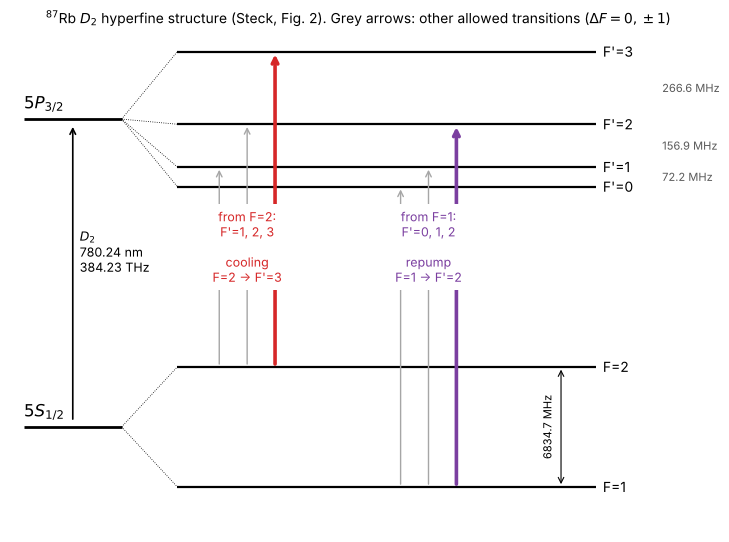

In [7]:
# Energy-level diagram (not to scale between the ground and excited states)
fig, ax = plt.subplots(figsize=(9, 6.5)); ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 10)
ytop = lambda e: 6.9 + (e + 302)/496*2.7
ybot = lambda g: 0.9 + (g + 4272)/6835*2.4
ax.hlines(8.25, 0.2, 1.6, color="k", lw=2); ax.text(0.2, 8.45, r"$5P_{3/2}$", fontsize=12)
ax.hlines(2.1, 0.2, 1.6, color="k", lw=2);  ax.text(0.2, 2.3, r"$5S_{1/2}$", fontsize=12)
ax.annotate("", xy=(0.9, 8.15), xytext=(0.9, 2.2), arrowprops=dict(arrowstyle="->", lw=1.2))
ax.text(1.0, 5.2, "$D_2$\n780.24 nm\n384.23 THz", fontsize=9)
for F, e in EXCITED.items():
    ax.plot([1.6, 2.4], [8.25, ytop(e)], "k:", lw=0.6); ax.hlines(ytop(e), 2.4, 8.4, color="k", lw=1.6)
    ax.text(8.5, ytop(e), f"F'={F}", va="center", fontsize=10)
for F, g in GROUND.items():
    ax.plot([1.6, 2.4], [2.1, ybot(g)], "k:", lw=0.6); ax.hlines(ybot(g), 2.4, 8.4, color="k", lw=1.6)
    ax.text(8.5, ybot(g), f"F={F}", va="center", fontsize=10)
# spacings between the excited levels
for (a, b), d in SPACING.items():
    ym = (ytop(EXCITED[a]) + ytop(EXCITED[b]))/2
    ax.text(9.35, ym, f"{d:.1f} MHz", va="center", fontsize=8, color="0.35")
ax.annotate("", xy=(7.9, ybot(GROUND[2])), xytext=(7.9, ybot(GROUND[1])), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax.text(7.8, 2.1, "6834.7 MHz", rotation=90, va="center", ha="right", fontsize=8)
for i, Fp in enumerate((1, 2, 3)):
    x = 3.0 + 0.4*i; c, lw = (COOL, 2.6) if Fp == 3 else ("0.65", 1.0)
    ax.annotate("", xy=(x, ytop(EXCITED[Fp])), xytext=(x, ybot(GROUND[2])), arrowprops=dict(arrowstyle="->", color=c, lw=lw))
for i, Fp in enumerate((0, 1, 2)):
    x = 5.6 + 0.4*i; c, lw = (REPUMP, 2.6) if Fp == 2 else ("0.65", 1.0)
    ax.annotate("", xy=(x, ytop(EXCITED[Fp])), xytext=(x, ybot(GROUND[1])), arrowprops=dict(arrowstyle="->", color=c, lw=lw))
ax.text(3.4, 5.0, "from F=2:\nF'=1, 2, 3\n\ncooling\nF=2 → F'=3", ha="center", color=COOL, fontsize=9, bbox=dict(fc="white", ec="none"))
ax.text(6.0, 5.0, "from F=1:\nF'=0, 1, 2\n\nrepump\nF=1 → F'=2", ha="center", color=REPUMP, fontsize=9, bbox=dict(fc="white", ec="none"))
ax.set_title(r"$^{87}$Rb $D_2$ hyperfine structure (Steck, Fig. 2). Grey arrows: other allowed transitions ($\Delta F=0,\pm1$)", fontsize=10)
fig.savefig(f"{FIG_DIR}/fig01_level_diagram.png", bbox_inches="tight"); plt.show()

### Why six peaks when only three transitions are allowed?

Each spectrum shows the three allowed transitions **plus three crossover resonances**. A crossover appears **exactly
halfway between two transitions** that share the same ground state. It is a consequence of the setup: the pump and
probe beams travel in **opposite directions**. When the laser is tuned halfway between two transitions, atoms moving
along the beam see one beam Doppler-shifted onto one transition and the other beam onto the other transition, so the
pump burns a hole that the probe detects. There is **no energy level** at a crossover; it only exists because of the
counter-propagating beams. Three transitions give three pairs, so **3 transitions + 3 crossovers = 6 peaks**.

### The literature frequencies of the six peaks ($\nu_{\rm theo}$)

The literature gives the **spacings** between the levels. The frequency of each peak is therefore given relative to the
**first (lowest-frequency) peak** of its spectrum, so all values are positive:

* $F=2$ spectrum: measured from $F=2\rightarrow F'=1$,
* $F=1$ spectrum: measured from $F=1\rightarrow F'=0$.

A crossover is the average of the two transitions it sits between, e.g. CO(1,2) $= (\nu_{F'=1} + \nu_{F'=2})/2$.

In [8]:
def six_peaks(F, Fps):
    # Literature frequencies (MHz) of the six peaks from ground state F, relative to the first peak
    a, b, c = Fps
    fa, fb, fc = [LEVEL[x] - LEVEL[a] for x in (a, b, c)]       # transitions, from Steck's spacings
    labels = [f"F'={a}", f"CO({a},{b})", f"F'={b}", f"CO({a},{c})", f"CO({b},{c})", f"F'={c}"]
    nu = np.array([fa, (fa + fb)/2, fb, (fa + fc)/2, (fb + fc)/2, fc])
    first_abs = NU_D2 + EXCITED[a] - GROUND[F]                    # absolute frequency of the first peak (MHz)
    return labels, nu, first_abs

LIT = {"F2": six_peaks(2, (1, 2, 3)), "F1": six_peaks(1, (0, 1, 2))}
NAME = {"F2": "$^{87}$Rb F=2 → F'", "F1": "$^{87}$Rb F=1 → F'"}
FIRST = {"F2": "F'=1", "F1": "F'=0"}                                  # the zero of each frequency axis
TARGET = {"F2": "F'=3", "F1": "F'=2"}                                 # cooling / repump transition
TARGET_TEXT = {"F2": "cooling transition F=2 → F'=3", "F1": "repump transition F=1 → F'=2"}
TARGET_COL = {"F2": COOL, "F1": REPUMP}

rows = []
for key in LIT:
    labels, nu, first_abs = LIT[key]
    for l, n in zip(labels, nu):
        role = TARGET_TEXT[key] if l == TARGET[key] else ""
        rows.append({"spectrum": NAME[key].replace("$^{87}$", "87"), "peak": l,
                     "type": "crossover" if l.startswith("CO") else "transition",
                     "ν_theo (MHz, from first peak)": round(n, 3),
                     "absolute frequency (THz)": round((first_abs + n)/1e6, 6), "note": role})
lit_table = pd.DataFrame(rows)
display(lit_table)

,spectrum,peak,type,"ν_theo (MHz, from first peak)",absolute frequency (THz),note
0,87Rb F=2 → F',F'=1,transition,0.000,384.227692,
1,87Rb F=2 → F',"CO(1,2)",crossover,78.474,384.227770,
2,87Rb F=2 → F',F'=2,transition,156.947,384.227849,
3,87Rb F=2 → F',"CO(1,3)",crossover,211.798,384.227903,
4,87Rb F=2 → F',"CO(2,3)",crossover,290.272,384.227982,
5,87Rb F=2 → F',F'=3,transition,423.597,384.228115,cooling transition F=2 → F'=3
6,87Rb F=1 → F',F'=0,transition,0.000,384.234454,
7,87Rb F=1 → F',"CO(0,1)",crossover,36.109,384.234490,
8,87Rb F=1 → F',F'=1,transition,72.218,384.234526,
9,87Rb F=1 → F',"CO(0,2)",crossover,114.583,384.234569,


* $\nu_{\rm theo}$ is the **theoretical (literature) value**. These are the six numbers the measured peaks are compared
  with in the calibration.
* The **cooling transition** $F=2\rightarrow F'=3$ sits 423.6 MHz above the first peak of the $F=2$ spectrum, and the
  **repump transition** $F=1\rightarrow F'=2$ sits 229.2 MHz above the first peak of the $F=1$ spectrum.
* The absolute frequencies show that the cooling transition (384.228 THz) and the repump transition (384.235 THz) are
  about 6.6 GHz apart, too far for one locked laser, which is why a MOT uses two lasers.

## 2. The full scan: what the blue and orange lines are

Before zooming in, the laser frequency was swept over the whole $D_2$ line (about 10 GHz). Two snapshots were saved:
**F0000** with the pump beam on and **F0001** with the pump beam blocked.

### 2a. Photodetector signal (blue) and piezo ramp (orange), F0000

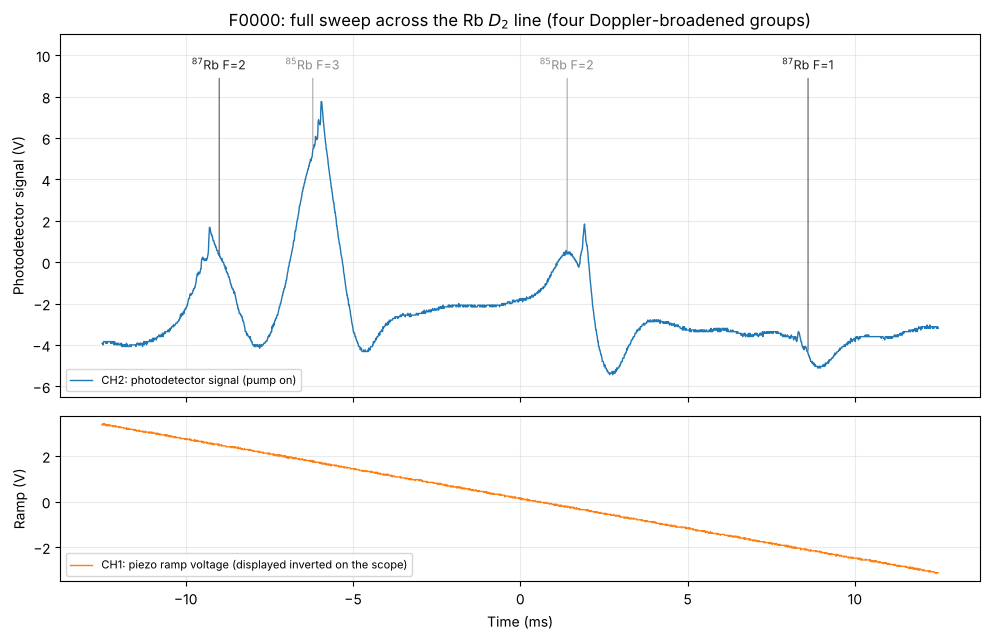

The ramp is a straight line: rms deviation 19 mV (scope step 40 mV)


In [9]:
t, on = load_trace(FULL_ON)
_, ramp = load_trace(FULL_RAMP)
_, off = load_trace(FULL_OFF)

# The four Doppler groups, left to right in time (the laser frequency increases with time)
GROUPS = [("$^{87}$Rb F=2", RB87), ("$^{85}$Rb F=3", RB85), ("$^{85}$Rb F=2", RB85), ("$^{87}$Rb F=1", RB87)]
GROUP_T = [-9.0, -6.2, 1.4, 8.6]      # approximate centre of each group (ms)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
a1.plot(t, on, color=BLUE, label="CH2: photodetector signal (pump on)")
for (lab, c), tg in zip(GROUPS, GROUP_T):
    a1.annotate(lab, xy=(tg, np.interp(tg, t, on)), xytext=(tg, 9.3), ha="center", fontsize=9, color=c,
                arrowprops=dict(arrowstyle="-", color=c, lw=0.6))
a1.set_ylim(-6.5, 11); a1.set_ylabel("Photodetector signal (V)"); a1.legend(loc="lower left", fontsize=8)
a1.set_title("F0000: full sweep across the Rb $D_2$ line (four Doppler-broadened groups)")
a2.plot(t, ramp, color=ORANGE, label="CH1: piezo ramp voltage (displayed inverted on the scope)")
a2.set_ylabel("Ramp (V)"); a2.set_xlabel("Time (ms)"); a2.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig02_full_scan_signal_ramp.png"); plt.show()
p = np.polyfit(t, ramp, 1)
print(f"The ramp is a straight line: rms deviation {1e3*np.std(ramp - np.polyval(p, t)):.0f} mV (scope step 40 mV)")

* **Blue (CH2)** is the photodetector signal: how much probe light gets through the rubidium cell.
* **Orange (CH1)** is the voltage ramp on the piezo behind the laser's grating. The ramp tilts the grating and so
  **changes the laser frequency to probe the different transitions**. It is a straight line, so the frequency changes at a
  constant rate in time, which is why a straight-line calibration (Section 6) works.
* The four broad features are the four **Doppler-broadened groups**, one for each ground state of each isotope (the cell
  contains natural rubidium). The **two outer groups are $^{87}$Rb** (ground states $F=2$ and $F=1$, 6.8 GHz apart); the
  **two inner groups are $^{85}$Rb** ($F=3$ and $F=2$, 3.0 GHz apart, and stronger because 72 % of rubidium is $^{85}$Rb).
* The small sharp spikes on top of the groups are the Doppler-free hyperfine features.

### 2b. Pump on (blue) versus pump blocked (orange)

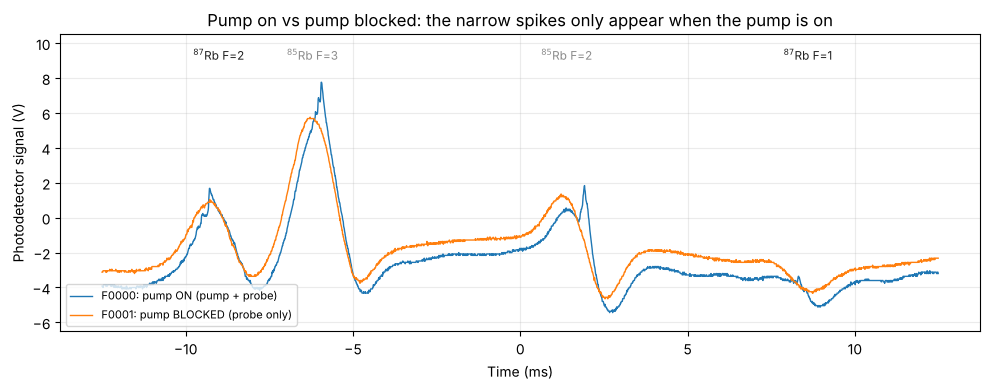

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, on, color=BLUE, label="F0000: pump ON (pump + probe)")
ax.plot(t, off, color=ORANGE, label="F0001: pump BLOCKED (probe only)")
for (lab, c), tg in zip(GROUPS, GROUP_T):
    ax.text(tg, 9.0, lab, ha="center", fontsize=8.5, color=c)
ax.set_ylim(-6.5, 10.5); ax.set_xlabel("Time (ms)"); ax.set_ylabel("Photodetector signal (V)")
ax.set_title("Pump on vs pump blocked: the narrow spikes only appear when the pump is on"); ax.legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig03_pump_on_vs_blocked.png"); plt.show()

* **Orange = pump blocked (ordinary absorption).** Only the weak probe crosses the cell. Atoms moving at different
  velocities absorb at different (Doppler-shifted) frequencies, so each group is a broad Doppler profile (about 500 MHz
  wide) and the hyperfine structure is hidden inside it.
* **Blue = pump on (saturated absorption).** The strong pump (90 % of the light) and the weak probe (10 %) cross the cell
  in opposite directions. Exactly on a transition, both beams interact with the same atoms, those at rest along the beam.
  The pump excites so many of them that their ground state is emptied (**hole burning / saturation**), so the probe is
  absorbed less and **more light reaches the detector**: a narrow peak appears at each hyperfine transition.
* The orange trace is slightly shifted sideways because it was recorded at a different time and the free-running
  **laser frequency drifted**.

### 2c. Blue minus orange: removing the Doppler background

Subtracting the pump-blocked signal from the pump-on signal removes the broad Doppler background and leaves only the
Doppler-free (saturated absorption) features. Because of the drift, the orange trace is first lined up with the blue one
(a small time shift, stretch, scale and offset are fitted) and then subtracted.

In the laboratory the same subtraction is done by the electronics: one photodiode sees the probe (overlapping the pump)
and a second sees a reference beam that crosses the cell without the pump, and the difference goes to the oscilloscope.
The zoomed spectra (F0002 to F0007) were then recorded by **reducing the ramp amplitude** so that only one $^{87}$Rb group
fills the screen: the left-hand $F=2$ group and the right-hand $F=1$ group.

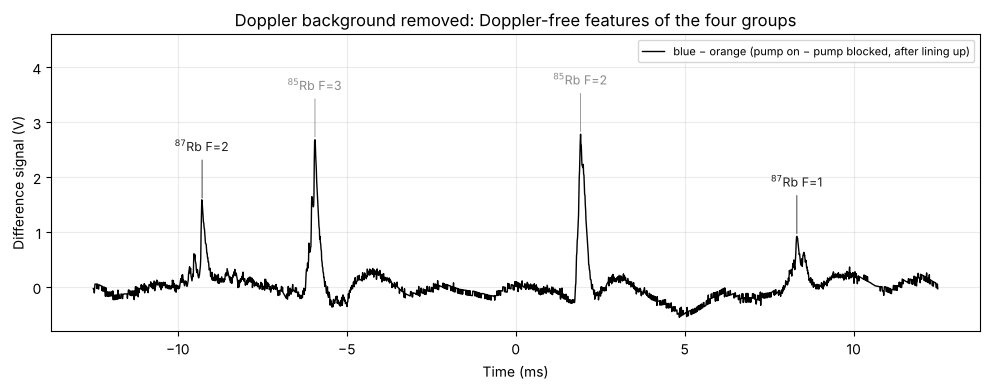

Full-sweep scan rate ≈ 376 MHz/ms (whole 25 ms window ≈ 9.4 GHz)
Shift between the two snapshots: 0.184 ms ≈ 69 MHz of laser drift between the two captures


In [11]:
off_s = savgol_filter(off, 51, 3)
def matched(p):
    scale, offset, stretch, shift = p
    return scale*np.interp(shift + stretch*t, t, off_s) + offset
sol = least_squares(lambda p: on - matched(p), [1, 0, 1, 0], loss="soft_l1", f_scale=0.3)
diff = on - matched(sol.x)
drift_ms = sol.x[3]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, diff, color="k", label="blue − orange (pump on − pump blocked, after lining up)")
pk, pr = find_peaks(savgol_filter(diff, 7, 2), prominence=0.5, distance=100)
pk = np.sort(pk[np.argsort(pr["prominences"])[-4:]])
for (lab, c), i in zip(GROUPS, pk):
    ax.annotate(lab, xy=(t[i], diff[i]), xytext=(t[i], diff[i] + 0.9), ha="center", fontsize=9, color=c,
                arrowprops=dict(arrowstyle="-", color=c, lw=0.6))
ax.set_ylim(-0.8, 4.6); ax.set_xlabel("Time (ms)"); ax.set_ylabel("Difference signal (V)")
ax.set_title("Doppler background removed: Doppler-free features of the four groups"); ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig04_full_scan_difference.png"); plt.show()

# Scan rate of the full sweep, from the strongest 87Rb peak of each group (their spacing is known from Steck)
co_F2 = (EXCITED[2] + EXCITED[3])/2 - GROUND[2]     # CO(2,3) of the F=2 group
co_F1 = (EXCITED[1] + EXCITED[2])/2 - GROUND[1]     # CO(1,2) of the F=1 group
FULL_RATE = (co_F1 - co_F2)/(t[pk[3]] - t[pk[0]])
drift_MHz = abs(drift_ms)*FULL_RATE
print(f"Full-sweep scan rate ≈ {FULL_RATE:.0f} MHz/ms (whole 25 ms window ≈ {FULL_RATE*25/1000:.1f} GHz)")
print(f"Shift between the two snapshots: {abs(drift_ms):.3f} ms ≈ {drift_MHz:.0f} MHz of laser drift between the two captures")

## 3. The $^{87}$Rb $F=2$ spectrum (contains the cooling transition)

Three runs (F0002, F0003, F0004) of the same measurement were recorded. **One run (F0002) is shown step by step**; the
other two are analysed in exactly the same way and used for the averages.

**Two line shapes, for two physical reasons:**

* **Gaussian** for the broad background: the Doppler profile comes from the Maxwell-Boltzmann distribution of atomic
  velocities, which is Gaussian. (A constant and a straight line are added for the scope offset and any tilt.)
* **Lorentzian** for each narrow peak: once the Doppler broadening is removed, a peak's shape is set by the finite
  lifetime of the excited state (26 ns), which gives a **Lorentzian**. We fit the peaks because a fit extracts the best
  values of the parameters of this model, and the parameter we need is the **centroid** (the peak position).

$$G(t)=a\,e^{-(t-\mu)^2/2\sigma^2},\qquad L(t)=\frac{S}{\pi}\,\frac{w/2}{(t-t_0)^2+(w/2)^2}$$

$S$ is the area, $t_0$ the **centroid** and $w$ the full width at half maximum (FWHM). The height of a Lorentzian is
$2S/(\pi w)$, so area and height are not the same thing.

**Starting values.** `curve_fit` needs a first guess for every parameter: the rough peak positions are read off the
raw plot (below), the starting width is 0.3 ms, and the starting area is worked out from the peak height.

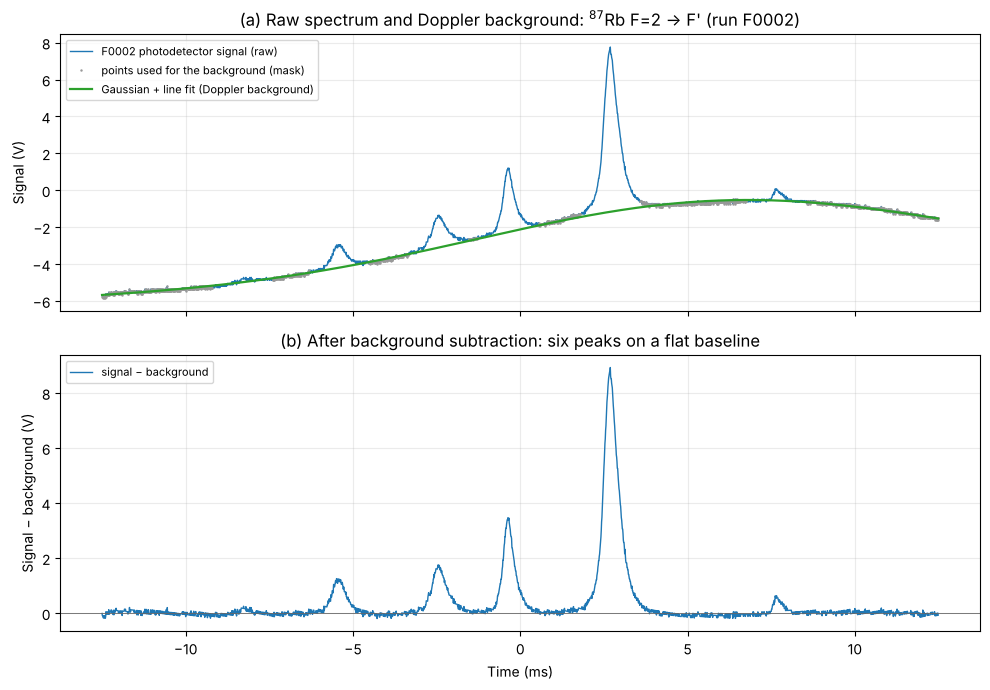

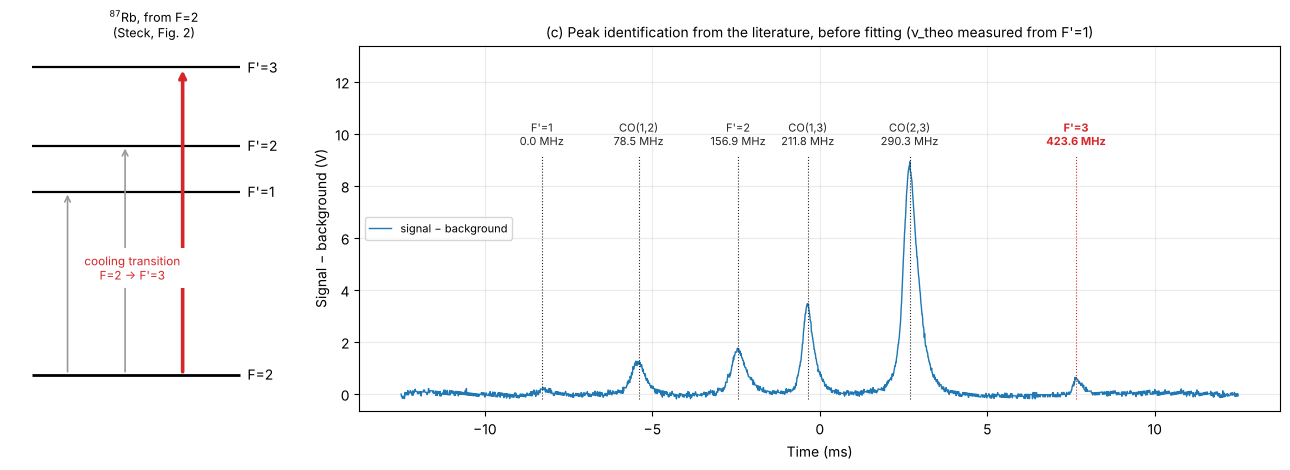

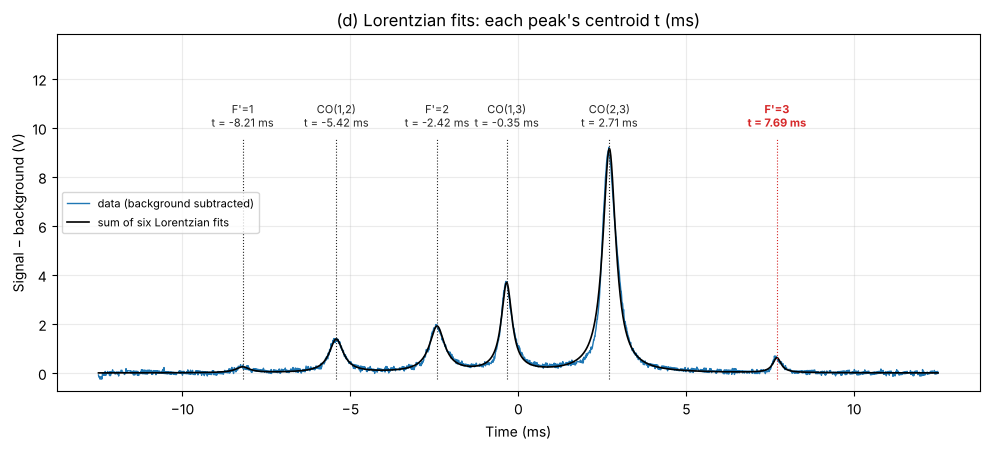

In [12]:
def gaussian(x, amplitude, mean, stddev):
    return amplitude*np.exp(-(x - mean)**2/(2*stddev**2))

def lorentzian(x, area, centroid, width):
    return (area/np.pi)*(0.5*width)/((x - centroid)**2 + (0.5*width)**2)

def background(x, amplitude, mean, stddev, offset, slope):
    return gaussian(x, amplitude, mean, stddev) + offset + slope*x

def full_model(x, *p):
    # Doppler background (5 parameters) + six Lorentzians (area, centroid, width each)
    y = background(x, *p[:5])
    for i in range(5, len(p), 3):
        y = y + lorentzian(x, *p[i:i+3])
    return y

# Rough peak positions (ms) read off the raw plots: starting guesses only
SEEDS = {
    "F0002CH2.CSV": [-8.30, -5.41, -2.44, -0.36, 2.68, 7.65],
    "F0003CH2.CSV": [-8.29, -5.47, -2.49, -0.47, 2.44, 7.57],
    "F0004CH2.CSV": [-8.35, -5.41, -2.72, -0.60, 2.38, 7.54],
    "F0005CH2.CSV": [-6.79, -4.79, -2.73, -0.38, 1.44, 5.99],
    "F0006CH2.CSV": [-7.97, -6.07, -3.68, -1.53, 0.48, 4.60],
    "F0007CH2.CSV": [-7.04, -4.89, -2.84, -0.57, 1.37, 5.41],
}

def fit_spectrum(fname):
    x, y = load_trace(fname)
    seeds = SEEDS[fname]
    # Step 1: mask = True where there are no peaks (more than 0.9 ms away from every peak)
    mask = np.ones_like(x, dtype=bool)
    for c in seeds:
        mask &= np.abs(x - c) > 0.9
    # Step 2: fit the Gaussian background to the masked points only, and subtract it
    p_bg, _ = curve_fit(background, x[mask], y[mask], p0=[4, 5, 8, -5, 0], maxfev=20000)
    y_sub = y - background(x, *p_bg)
    # Step 3: fit background + six Lorentzians together, starting from step 2
    p0, lo, hi = list(p_bg), [-np.inf]*5, [np.inf]*5
    for c in seeds:
        h = max(np.interp(c, x, y_sub), 0.05)
        p0 += [h*np.pi*0.3/2, c, 0.3]; lo += [0, c - 0.5, 0.05]; hi += [np.inf, c + 0.5, 3.0]
    popt, pcov = curve_fit(full_model, x, y, p0=p0, bounds=(lo, hi), maxfev=100000)
    perr = np.sqrt(np.diag(pcov))
    return dict(x=x, y=y, mask=mask, p_bg=p_bg, y_sub=y_sub, popt=popt, seeds=seeds,
                y_sub_final=y - background(x, *popt[:5]),
                centroid=popt[6::3], centroid_err=perr[6::3], fwhm=popt[7::3],
                height=2*popt[5::3]/(np.pi*popt[7::3]))

FITS = {f: fit_spectrum(f) for f in FILES["F2"] + FILES["F1"]}

def draw_levels(ax, key):
    # small level diagram for one ground state, with the target transition in colour
    F, Fps = (2, (1, 2, 3)) if key == "F2" else (1, (0, 1, 2))
    col = TARGET_COL[key]; ax.axis("off"); ax.set_xlim(0, 4); ax.set_ylim(0, 10)
    lo_e, hi_e = EXCITED[Fps[0]], EXCITED[Fps[-1]]
    yl = lambda e: 6.0 + (e - lo_e)/(hi_e - lo_e)*3.4
    ax.hlines(1.0, 0.3, 3.2, color="k", lw=2); ax.text(3.3, 1.0, f"F={F}", va="center", fontsize=10)
    for i, Fp in enumerate(Fps):
        ax.hlines(yl(EXCITED[Fp]), 0.3, 3.2, color="k", lw=1.6)
        ax.text(3.3, yl(EXCITED[Fp]), f"F'={Fp}", va="center", fontsize=10)
        c, lw = (col, 2.6) if f"F'={Fp}" == TARGET[key] else ("0.6", 1.2)
        ax.annotate("", xy=(0.8 + 0.8*i, yl(EXCITED[Fp])), xytext=(0.8 + 0.8*i, 1.0), arrowprops=dict(arrowstyle="->", color=c, lw=lw))
    ax.text(1.7, 3.6, TARGET_TEXT[key].replace("transition ", "transition\n"), ha="center", fontsize=8.5, color=col,
            bbox=dict(fc="white", ec="none"))
    ax.set_title(f"$^{{87}}$Rb, from F={F}\n(Steck, Fig. 2)", fontsize=9)

def show_steps(key):
    f = SHOW[key]; r = FITS[f]; lab, nu, _ = LIT[key]; col = TARGET_COL[key]
    x, y = r["x"], r["y"]
    # Figure 1: background
    fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    axs[0].plot(x, y, color=BLUE, label=f"{f[:5]} photodetector signal (raw)")
    axs[0].plot(x[r["mask"]], y[r["mask"]], ".", ms=1.5, color="0.6", label="points used for the background (mask)")
    axs[0].plot(x, background(x, *r["p_bg"]), color=BG, lw=1.6, label="Gaussian + line fit (Doppler background)")
    axs[0].set_ylabel("Signal (V)"); axs[0].legend(fontsize=8, loc="upper left")
    axs[0].set_title(f"(a) Raw spectrum and Doppler background: {NAME[key]} (run {f[:5]})")
    axs[1].plot(x, r["y_sub"], color=BLUE, label="signal − background")
    axs[1].axhline(0, color="0.4", lw=0.6); axs[1].set_ylabel("Signal − background (V)"); axs[1].set_xlabel("Time (ms)")
    axs[1].legend(fontsize=8, loc="upper left"); axs[1].set_title("(b) After background subtraction: six peaks on a flat baseline")
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_{key}_a_background.png"); plt.show()

    # Figure 2: peaks labelled from the literature BEFORE the fit, next to the level diagram
    fig, (axl, axs2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 3.2]})
    draw_levels(axl, key)
    ys = r["y_sub"]; top = ys.max()
    axs2.plot(x, ys, color=BLUE, label="signal − background")
    for l, n, s in zip(lab, nu, r["seeds"]):
        is_t = (l == TARGET[key]); cc = col if is_t else "0.15"
        axs2.vlines(s, ys.min(), top*1.03, color=cc, ls=":", lw=0.8)
        axs2.text(s, top*1.06, f"{l}\n{n:.1f} MHz", ha="center", va="bottom", fontsize=8, color=cc,
                  fontweight="bold" if is_t else "normal")
    axs2.set_ylim(top=top*1.5); axs2.set_xlabel("Time (ms)"); axs2.set_ylabel("Signal − background (V)")
    axs2.set_title(f"(c) Peak identification from the literature, before fitting (ν_theo measured from {FIRST[key]})", fontsize=10)
    axs2.legend(fontsize=8, loc="center left")
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_{key}_b_labels.png"); plt.show()

    # Figure 3: Lorentzian fit with centroids
    ys = r["y_sub_final"]; top = ys.max()
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.plot(x, ys, color=BLUE, label="data (background subtracted)")
    ax.plot(x, full_model(x, *r["popt"]) - background(x, *r["popt"][:5]), color=FIT, lw=1.2, label="sum of six Lorentzian fits")
    for l, c in zip(lab, r["centroid"]):
        is_t = (l == TARGET[key]); cc = col if is_t else "0.15"
        ax.vlines(c, ys.min(), top*1.04, color=cc, ls=":", lw=0.8)
        ax.text(c, top*1.08, f"{l}\nt = {c:.2f} ms", ha="center", va="bottom", fontsize=8, color=cc,
                fontweight="bold" if is_t else "normal")
    ax.set_ylim(top=top*1.5); ax.set_ylabel("Signal − background (V)"); ax.set_xlabel("Time (ms)")
    ax.legend(fontsize=8, loc="center left")
    ax.set_title("(d) Lorentzian fits: each peak's centroid t (ms)")
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig_{key}_c_fit.png"); plt.show()

show_steps("F2")

* (a) The peaks sit on the edge of the Doppler profile. The grey points (away from the peaks) define the background.
* (b) After subtracting the background, the six peaks sit on a flat line.
* (c) Each peak is identified from the literature **before** fitting. Reading left to right (frequency increases with
  time): $F'=1$, CO(1,2), $F'=2$, CO(1,3), CO(2,3), $F'=3$. The **cooling transition $F=2\rightarrow F'=3$ is the small
  peak on the far right**. The tallest peak is the crossover CO(2,3), which lies halfway between $F'=2$ and $F'=3$.
* (d) The Lorentzian fit gives the centroid of every peak in milliseconds.

## 4. The $^{87}$Rb $F=1$ spectrum (contains the repump transition)

Three runs (F0005, F0006, F0007); **F0005 is shown**. The background is almost flat because $F=1$ is the weakest
absorption group: it belongs to the less abundant isotope and holds fewer atoms than $F=2$.

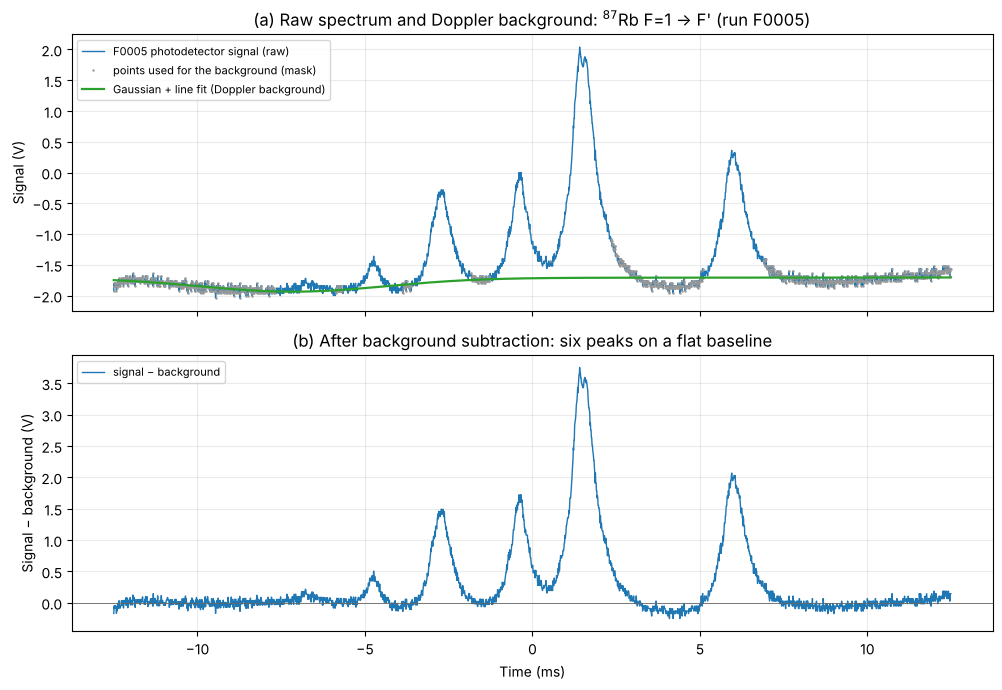

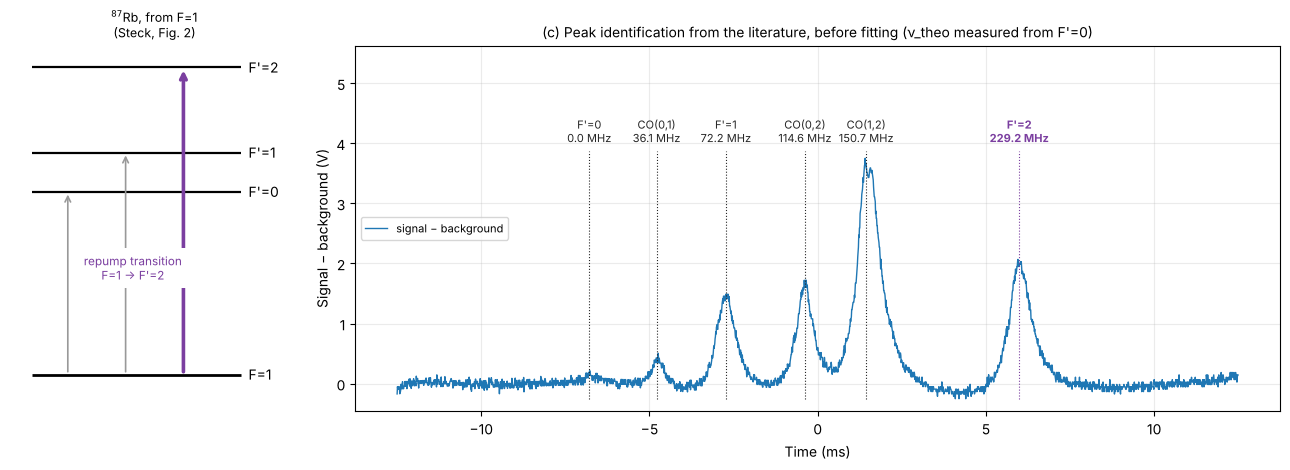

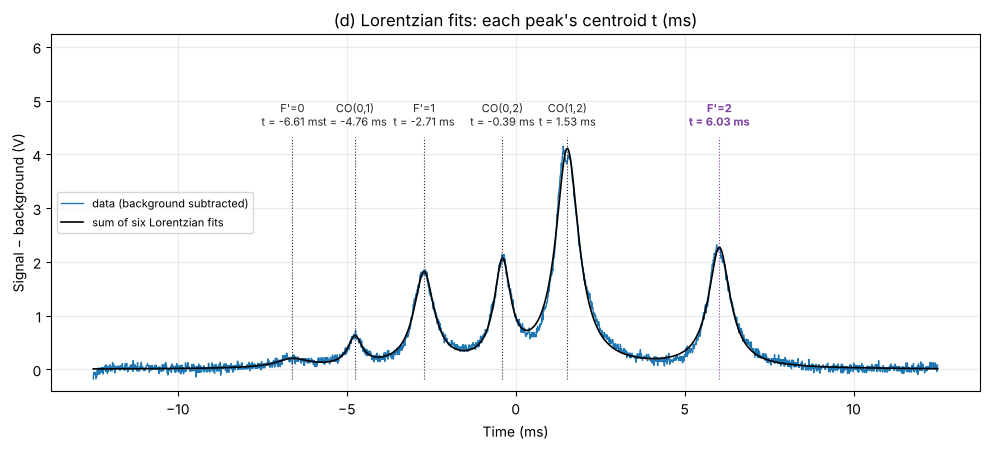

In [13]:
show_steps("F1")

Left to right: $F'=0$, CO(0,1), $F'=1$, CO(0,2), CO(1,2), $F'=2$. The **repump transition $F=1\rightarrow F'=2$ is the
peak on the far right**; the tallest peak is the crossover CO(1,2), halfway between $F'=1$ and $F'=2$.

## 5. Centroid table

The centroid of each peak, for all three runs, with the fit uncertainty from `curve_fit` (the square root of the
diagonal of the covariance matrix `pcov`). The last two columns are the mean of the three runs and its standard error
(SEM = standard deviation / $\sqrt{3}$). The runs do not line up exactly in time because the laser drifts and each sweep
is slightly different, so each run is calibrated on its own in Section 6.

In [14]:
rows = []
for key in FILES:
    for f in FILES[key]:
        r = FITS[f]
        for l, c, ce, w, h in zip(LIT[key][0], r["centroid"], r["centroid_err"], r["fwhm"], r["height"]):
            rows.append(dict(spectrum=key, run=f[:5], peak=l, centroid_ms=c, centroid_err_ms=ce, fwhm_ms=w, height_V=h))
peaks = pd.DataFrame(rows)

centroid_tables = {}
for key in FILES:
    d = peaks[peaks.spectrum == key]
    tab = pd.DataFrame(index=LIT[key][0]); tab.index.name = "peak"
    tab["type"] = ["crossover" if p.startswith("CO") else "transition" for p in tab.index]
    for f in FILES[key]:
        run = d[d.run == f[:5]].set_index("peak")
        tab[f"{f[:5]} t (ms)"] = [f"{run.loc[p, 'centroid_ms']:.3f} ± {run.loc[p, 'centroid_err_ms']:.3f}" for p in tab.index]
    piv = d.pivot(index="peak", columns="run", values="centroid_ms").reindex(tab.index)
    tab["mean (ms)"] = piv.mean(axis=1).round(3)
    tab["SEM (ms)"] = (piv.std(axis=1, ddof=1)/np.sqrt(piv.shape[1])).round(3)
    centroid_tables[key] = tab
    print(f"\nCentroids: {NAME[key].replace('$^{87}$', '87')} (three runs)")
    display(tab)
pd.concat(centroid_tables, names=["spectrum"]).to_csv("centroid_table.csv")


Centroids: 87Rb F=2 → F' (three runs)


,type,F0002 t (ms),F0003 t (ms),F0004 t (ms),mean (ms),SEM (ms)
peak,,,,,,
F'=1,transition,-8.211 ± 0.028,-8.336 ± 0.019,-8.365 ± 0.016,-8.304,0.047
"CO(1,2)",crossover,-5.422 ± 0.005,-5.447 ± 0.004,-5.411 ± 0.004,-5.427,0.011
F'=2,transition,-2.422 ± 0.004,-2.478 ± 0.003,-2.693 ± 0.003,-2.531,0.083
"CO(1,3)",crossover,-0.350 ± 0.002,-0.454 ± 0.001,-0.579 ± 0.001,-0.461,0.066
"CO(2,3)",crossover,2.707 ± 0.001,2.454 ± 0.001,2.401 ± 0.001,2.521,0.094
F'=3,transition,7.694 ± 0.008,7.599 ± 0.007,7.567 ± 0.006,7.620,0.038



Centroids: 87Rb F=1 → F' (three runs)


,type,F0005 t (ms),F0006 t (ms),F0007 t (ms),mean (ms),SEM (ms)
peak,,,,,,
F'=0,transition,-6.608 ± 0.038,-7.942 ± 0.022,-7.043 ± 0.023,-7.198,0.393
"CO(0,1)",crossover,-4.757 ± 0.008,-6.038 ± 0.006,-4.874 ± 0.007,-5.223,0.409
F'=1,transition,-2.714 ± 0.003,-3.680 ± 0.002,-2.778 ± 0.002,-3.058,0.312
"CO(0,2)",crossover,-0.394 ± 0.002,-1.502 ± 0.002,-0.565 ± 0.002,-0.820,0.345
"CO(1,2)",crossover,1.527 ± 0.001,0.505 ± 0.001,1.364 ± 0.001,1.132,0.317
F'=2,transition,6.026 ± 0.002,4.631 ± 0.002,5.414 ± 0.002,5.357,0.404


## 6. Calibration: from time to frequency

The oscilloscope records voltage against **time**. A photodiode only measures light power, and no electronics can
follow an optical frequency of 384 THz, so the frequency cannot be read directly. Because the ramp sweeps the laser
frequency at a constant rate, **each time corresponds to one laser frequency**, and the known (literature) frequencies of
the peaks let us turn the time axis into a frequency axis.

### 6a. Rough check by hand

First a quick check with two real transitions whose spacing is known from Steck: for the $F=2$ spectrum,
$F'=2\rightarrow F'=3$ = 266.65 MHz; for the $F=1$ spectrum, $F'=1\rightarrow F'=2$ = 156.95 MHz. Dividing the
spacing by the time between the two centroids gives the scan rate. The time axis is then shifted so that the first
peak is at zero, and every centroid is converted. If the peaks are identified correctly, the other peaks must land close
to their literature values.

In [15]:
PAIR = {"F2": ("F'=2", "F'=3"), "F1": ("F'=1", "F'=2")}
for key in FILES:
    f = SHOW[key]; lab, nu, _ = LIT[key]; t_c = np.array(FITS[f]["centroid"])
    ia, ib = lab.index(PAIR[key][0]), lab.index(PAIR[key][1])
    rate = (nu[ib] - nu[ia])/(t_c[ib] - t_c[ia])                    # MHz per ms
    nu_rough = rate*(t_c - t_c[0])                                    # shift so the first peak is at 0
    print(f"\n{NAME[key].replace('$^{87}$', '87')} (run {f[:5]}): {PAIR[key][0]} → {PAIR[key][1]} is "
          f"{nu[ib]-nu[ia]:.2f} MHz in {t_c[ib]-t_c[ia]:.3f} ms  →  rough scan rate {rate:.2f} MHz/ms")
    display(pd.DataFrame({"peak": lab, "centroid t (ms)": t_c.round(3), "ν_rough (MHz)": nu_rough.round(1),
                          "ν_theo (MHz)": nu.round(1), "difference (MHz)": (nu_rough - nu).round(1)}))


87Rb F=2 → F' (run F0002): F'=2 → F'=3 is 266.65 MHz in 10.116 ms  →  rough scan rate 26.36 MHz/ms


,peak,centroid t (ms),ν_rough (MHz),ν_theo (MHz),difference (MHz)
0,F'=1,-8.211,0.0,0.0,0.0
1,"CO(1,2)",-5.422,73.5,78.5,-5.0
2,F'=2,-2.422,152.6,156.9,-4.4
3,"CO(1,3)",-0.350,207.2,211.8,-4.6
4,"CO(2,3)",2.707,287.8,290.3,-2.5
5,F'=3,7.694,419.2,423.6,-4.4



87Rb F=1 → F' (run F0005): F'=1 → F'=2 is 156.95 MHz in 8.740 ms  →  rough scan rate 17.96 MHz/ms


,peak,centroid t (ms),ν_rough (MHz),ν_theo (MHz),difference (MHz)
0,F'=0,-6.608,0.0,0.0,0.0
1,"CO(0,1)",-4.757,33.2,36.1,-2.9
2,F'=1,-2.714,69.9,72.2,-2.3
3,"CO(0,2)",-0.394,111.6,114.6,-3.0
4,"CO(1,2)",1.527,146.1,150.7,-4.6
5,F'=2,6.026,226.9,229.2,-2.3


The rough conversion already puts every peak within about 5 MHz of its literature value, so the peaks are identified
correctly. The straight-line fit below does the same thing properly, using all six peaks.

### 6b. The calibration fit

The steps (as explained by the supervisor):

1. **Centroids:** the fitted times $t_1 \dots t_6$ of the six peaks (Section 5).
2. **Literature values:** the array $\nu_{\rm theo} = [\nu_1 \dots \nu_6]$ in the same order (Section 1).
3. **Plot** $\nu_{\rm theo}$ (y-axis) against $t_{\rm fit}$ (x-axis): six data points.
4. **Fit a straight line** $\nu = a_0 + a_1\,t$ by least squares: $a_1$ is the **slope** (the scan rate, MHz per ms) and
   $a_0$ is the **y-intercept** (MHz).
5. **Fitted frequency of each peak:** $\nu_{\rm fit} = a_0 + a_1\,t_{\rm fit}$ for each of the six centroids.
6. **Compare** $|\nu_{\rm fit} - \nu_{\rm theo}|$: if the peaks are identified correctly this is only a few MHz.

Least squares chooses $a_0$ and $a_1$ to make $\sum_i [\nu_i - (a_0 + a_1 t_i)]^2$ as small as possible. For a straight
line this has an exact answer: $a_1 = \sum (t_i-\bar t)(\nu_i-\bar\nu) \,/\, \sum (t_i-\bar t)^2$ and $a_0 = \bar\nu - a_1 \bar t$.

In [16]:
CAL = {}
def calibrate(fname, key, use=None):
    # use = list of peak labels to fit (default: all six)
    lab, nu_theo, _ = LIT[key]
    t_fit = np.array(FITS[fname]["centroid"])
    sel = np.array([True]*6) if use is None else np.array([l in use for l in lab])
    X = np.column_stack([np.ones(sel.sum()), t_fit[sel]])
    (a0, a1), *_ = np.linalg.lstsq(X, nu_theo[sel], rcond=None)
    res = nu_theo[sel] - (a0 + a1*t_fit[sel])
    cov = np.sum(res**2)/max(sel.sum() - 2, 1)*np.linalg.inv(X.T @ X)   # uncertainty of a0 and a1
    sa0, sa1 = np.sqrt(np.diag(cov))
    nu_fit = a0 + a1*t_fit
    return dict(a0=a0, a1=a1, sa0=sa0, sa1=sa1, t_fit=t_fit, nu_theo=nu_theo, nu_fit=nu_fit, labels=lab)

for key in FILES:
    for f in FILES[key]:
        CAL[f] = calibrate(f, key)

for key in FILES:
    f = SHOW[key]; C = CAL[f]
    print(f"\n{NAME[key].replace('$^{87}$', '87')}, run {f[:5]}")
    print(f"   slope a1 = {C['a1']:.3f} ± {C['sa1']:.3f} MHz/ms     y-intercept a0 = {C['a0']:.2f} ± {C['sa0']:.2f} MHz")
    display(pd.DataFrame({"peak": C["labels"], "t_fit (ms)": C["t_fit"].round(3), "ν_theo (MHz)": C["nu_theo"].round(2),
                          "ν_fit = a0 + a1·t_fit (MHz)": C["nu_fit"].round(2),
                          "|ν_fit − ν_theo| (MHz)": np.abs(C["nu_fit"] - C["nu_theo"]).round(2)}))


87Rb F=2 → F', run F0002
   slope a1 = 26.494 ± 0.152 MHz/ms     y-intercept a0 = 220.02 ± 0.81 MHz


,peak,t_fit (ms),ν_theo (MHz),ν_fit = a0 + a1·t_fit (MHz),|ν_fit − ν_theo| (MHz)
0,F'=1,-8.211,0.00,2.49,2.49
1,"CO(1,2)",-5.422,78.47,76.38,2.09
2,F'=2,-2.422,156.95,155.85,1.10
3,"CO(1,3)",-0.350,211.80,210.76,1.04
4,"CO(2,3)",2.707,290.27,291.74,1.46
5,F'=3,7.694,423.60,423.87,0.27



87Rb F=1 → F', run F0005
   slope a1 = 18.121 ± 0.141 MHz/ms     y-intercept a0 = 121.36 ± 0.61 MHz


,peak,t_fit (ms),ν_theo (MHz),ν_fit = a0 + a1·t_fit (MHz),|ν_fit − ν_theo| (MHz)
0,F'=0,-6.608,0.00,1.61,1.61
1,"CO(0,1)",-4.757,36.11,35.16,0.95
2,F'=1,-2.714,72.22,72.17,0.04
3,"CO(0,2)",-0.394,114.58,114.23,0.35
4,"CO(1,2)",1.527,150.69,149.03,1.66
5,F'=2,6.026,229.17,230.56,1.40


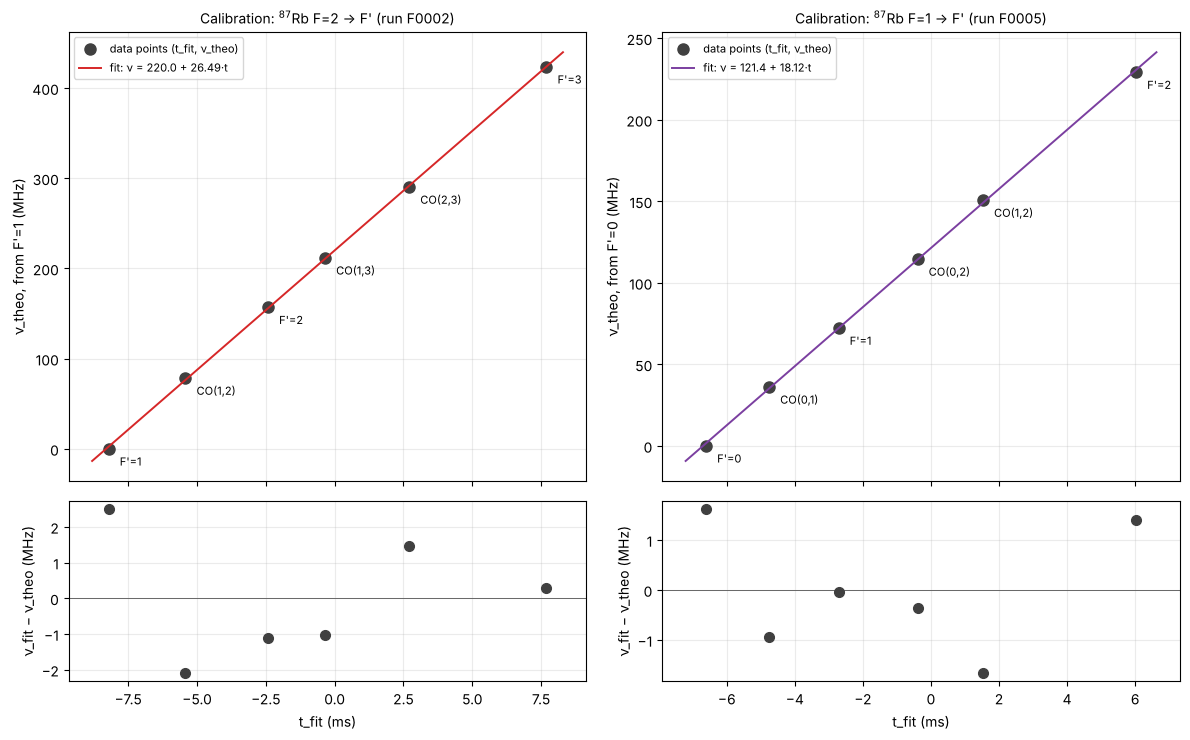

Calibration of all six runs:


,spectrum,run,slope a1 (MHz/ms),± a1,intercept a0 (MHz),± a0,max |ν_fit − ν_theo| (MHz)
0,F2,F0002,26.494,0.152,220.021,0.807,2.488
1,F2,F0003,26.612,0.117,223.063,0.619,1.891
2,F2,F0004,26.638,0.247,224.949,1.315,3.746
3,F1,F0005,18.121,0.141,121.361,0.611,1.660
4,F1,F0006,18.135,0.279,142.855,1.331,3.896
5,F1,F0007,18.463,0.283,126.565,1.224,3.480


In [17]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5), gridspec_kw={"height_ratios": [3, 1.2]}, sharex="col")
for col, key in enumerate(FILES):
    f = SHOW[key]; C = CAL[f]; c = TARGET_COL[key]
    tt = np.linspace(C["t_fit"].min() - 0.6, C["t_fit"].max() + 0.6, 50)
    axs[0, col].plot(C["t_fit"], C["nu_theo"], "o", ms=8, color="0.25", label="data points (t_fit, ν_theo)")
    axs[0, col].plot(tt, C["a0"] + C["a1"]*tt, "-", color=c, lw=1.4,
                     label=f"fit: ν = {C['a0']:.1f} + {C['a1']:.2f}·t")
    for l, ti, n in zip(C["labels"], C["t_fit"], C["nu_theo"]):
        axs[0, col].annotate(l, (ti, n), xytext=(8, -12), textcoords="offset points", fontsize=8)
    axs[0, col].set_ylabel(f"ν_theo, from {FIRST[key]} (MHz)")
    axs[0, col].set_title(f"Calibration: {NAME[key]} (run {f[:5]})", fontsize=10); axs[0, col].legend(fontsize=8, loc="upper left")
    axs[1, col].axhline(0, color="0.4", lw=0.7)
    axs[1, col].plot(C["t_fit"], C["nu_fit"] - C["nu_theo"], "o", ms=7, color="0.25")
    axs[1, col].set_ylabel("ν_fit − ν_theo (MHz)"); axs[1, col].set_xlabel("t_fit (ms)")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig07_calibration.png"); plt.show()

cal = pd.DataFrame([{"spectrum": k, "run": f[:5], "slope a1 (MHz/ms)": CAL[f]["a1"], "± a1": CAL[f]["sa1"],
                     "intercept a0 (MHz)": CAL[f]["a0"], "± a0": CAL[f]["sa0"],
                     "max |ν_fit − ν_theo| (MHz)": np.abs(CAL[f]["nu_fit"] - CAL[f]["nu_theo"]).max()}
                    for k in FILES for f in FILES[k]])
print("Calibration of all six runs:"); display(cal.round(3)); cal.to_csv("calibration_table.csv", index=False)

* The slope (scan rate) is about 26.6 MHz/ms for the $F=2$ spectra and 18.2 MHz/ms for the $F=1$ spectra: the ramp was
  set differently for the two. It also changes slightly from run to run, which is why every run gets its own calibration.
* $|\nu_{\rm fit} - \nu_{\rm theo}|$ stays below 4 MHz in every run (about 1.3 MHz rms over all peaks), over a range of
  424 MHz ($F=2$) and 229 MHz ($F=1$).
  The points lie on a straight line, so the peaks are identified correctly and the sweep is linear.
* Note: the line is fitted *to* the literature values, so this agreement confirms the identification and the linearity;
  it is not an independent measurement of the literature values. Section 6c is an independent test.

### 6c. Check: calibrate with the three real transitions only

The line is now fitted to the three real transitions only. The three crossovers are **not** used, so their predicted
positions are a genuine test: each crossover must fall **exactly halfway** between its two transitions.

In [18]:
for key in FILES:
    f = SHOW[key]; lab = LIT[key][0]
    real = [l for l in lab if not l.startswith("CO")]
    C3 = calibrate(f, key, use=real)
    rows = []
    for l, n_fit, n_theo in zip(lab, C3["nu_fit"], C3["nu_theo"]):
        if l.startswith("CO"):
            a, b = l[3], l[5]
            mid = (C3["nu_fit"][lab.index(f"F'={a}")] + C3["nu_fit"][lab.index(f"F'={b}")])/2
            rows.append({"crossover": l, "between": f"F'={a} and F'={b}",
                         "predicted from the line (MHz)": round(n_fit, 2),
                         "halfway between the two transitions (MHz)": round(mid, 2),
                         "literature (MHz)": round(n_theo, 2), "predicted − literature (MHz)": round(n_fit - n_theo, 2)})
    df = pd.DataFrame(rows)
    print(f"\n{NAME[key].replace('$^{87}$', '87')}, run {f[:5]}: line through {real} → a1 = {C3['a1']:.3f} MHz/ms")
    display(df)


87Rb F=2 → F', run F0002: line through ["F'=1", "F'=2", "F'=3"] → a1 = 26.602 MHz/ms


,crossover,between,predicted from the line (MHz),halfway between the two transitions (MHz),literature (MHz),predicted − literature (MHz)
0,"CO(1,2)",F'=1 and F'=2,75.35,78.14,78.47,-3.13
1,"CO(1,3)",F'=1 and F'=3,210.27,212.70,211.80,-1.52
2,"CO(2,3)",F'=2 and F'=3,291.58,289.70,290.27,1.31



87Rb F=1 → F', run F0005: line through ["F'=0", "F'=1", "F'=2"] → a1 = 18.108 MHz/ms


,crossover,between,predicted from the line (MHz),halfway between the two transitions (MHz),literature (MHz),predicted − literature (MHz)
0,"CO(0,1)",F'=0 and F'=1,34.22,35.95,36.11,-1.89
1,"CO(0,2)",F'=0 and F'=2,113.23,115.09,114.58,-1.35
2,"CO(1,2)",F'=1 and F'=2,148.01,150.34,150.69,-2.68


The crossovers land within a few MHz of the halfway points and of the literature values, even though they were not used
in the fit. This confirms that the three extra peaks are crossovers, exactly halfway between the transitions.

### 6d. Convert the whole time axis to frequency

Every time value is put through $\nu = a_0 + a_1 t$ (multiply by $a_1$, add $a_0$), so the spectrum is now plotted against
frequency in MHz, with zero at the first peak and frequency increasing to the right. The dashed lines are the literature
positions; the dots are the fitted positions.

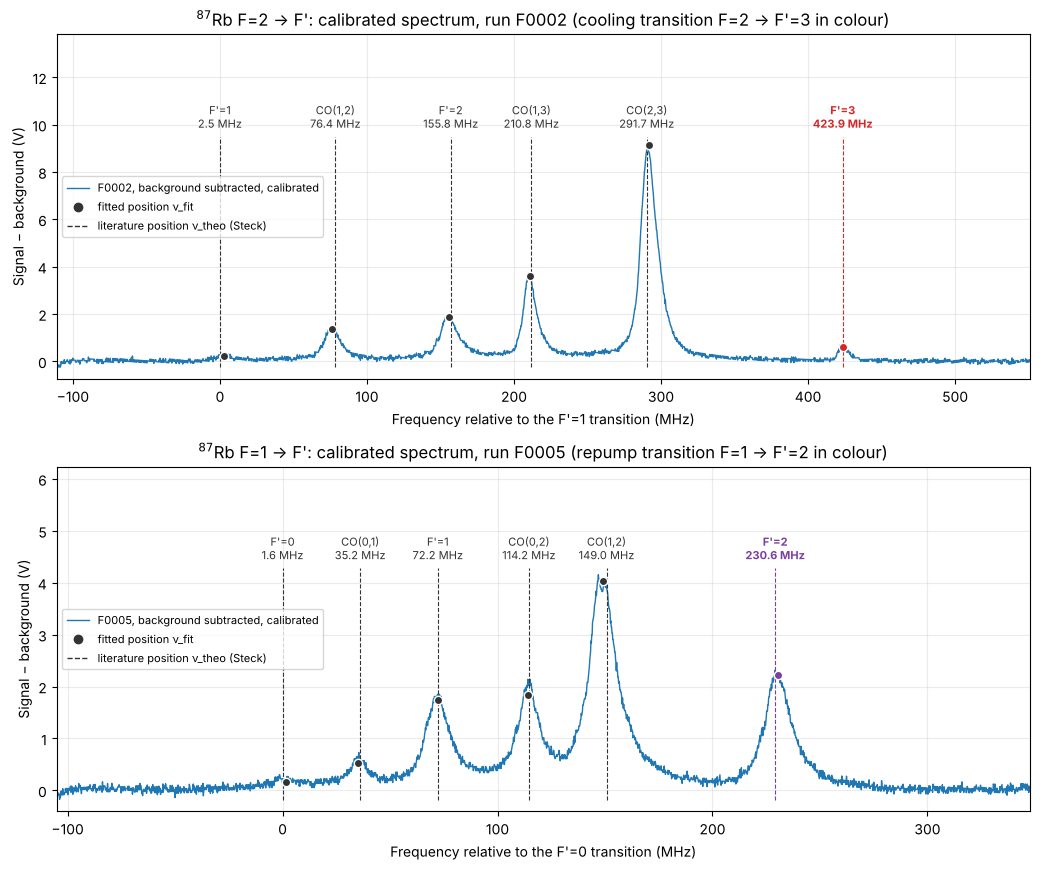

In [19]:
fig, axs = plt.subplots(2, 1, figsize=(10.5, 8.8))
for ax, key in zip(axs, FILES):
    f = SHOW[key]; r = FITS[f]; C = CAL[f]; col = TARGET_COL[key]
    nu_axis = C["a0"] + C["a1"]*r["x"]                     # the converted x-axis
    ys = r["y_sub_final"]; top = ys.max()
    ax.plot(nu_axis, ys, color=BLUE, label=f"{f[:5]}, background subtracted, calibrated")
    for l, n_fit, n_theo, h in zip(C["labels"], C["nu_fit"], C["nu_theo"], r["height"]):
        is_t = (l == TARGET[key]); cc = col if is_t else "0.2"
        ax.vlines(n_theo, ys.min(), top*1.03, color=cc, ls="--", lw=0.8)
        ax.plot(n_fit, h, "o", ms=6, color=cc, mec="white", mew=1, zorder=5)
        ax.text(n_theo, top*1.06, f"{l}\n{n_fit:.1f} MHz", ha="center", va="bottom", fontsize=8, color=cc,
                fontweight="bold" if is_t else "normal")
    ax.plot([], [], "o", color="0.2", label="fitted position ν_fit")
    ax.plot([], [], "--", color="0.2", label="literature position ν_theo (Steck)")
    ax.set_ylim(top=top*1.5); ax.set_xlim(nu_axis.min(), nu_axis.max())
    ax.set_xlabel(f"Frequency relative to the {FIRST[key]} transition (MHz)")
    ax.set_ylabel("Signal − background (V)")
    ax.set_title(f"{NAME[key]}: calibrated spectrum, run {f[:5]} ({TARGET_TEXT[key]} in colour)")
    ax.legend(fontsize=8, loc="center left")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/fig08_calibrated_spectra.png"); plt.show()

## 7. Results

### 7a. Frequencies of all peaks (three runs)

Each run is converted with its own calibration, then the three runs are averaged. The uncertainty is the standard error
of the three runs (SEM).

In [20]:
peaks["nu_fit_MHz"] = [CAL[f"{r}CH2.CSV"]["a0"] + CAL[f"{r}CH2.CSV"]["a1"]*c for r, c in zip(peaks.run, peaks.centroid_ms)]
peaks["fwhm_MHz"] = [CAL[f"{r}CH2.CSV"]["a1"]*w for r, w in zip(peaks.run, peaks.fwhm_ms)]
lit_lookup = {(k, l): n for k in LIT for l, n in zip(LIT[k][0], LIT[k][1])}

res = (peaks.groupby(["spectrum", "peak"], sort=False)
       .agg(nu_fit_mean=("nu_fit_MHz", "mean"),
            sem=("nu_fit_MHz", lambda v: v.std(ddof=1)/np.sqrt(len(v))),
            fwhm_MHz=("fwhm_MHz", "mean"))
       .reset_index())
res["nu_theo"] = [lit_lookup[(k, l)] for k, l in zip(res.spectrum, res.peak)]
res["difference"] = res.nu_fit_mean - res.nu_theo
res["note"] = [TARGET_TEXT[k] if l == TARGET[k] else "" for k, l in zip(res.spectrum, res.peak)]
out = res.rename(columns={"nu_fit_mean": "ν_fit, mean of 3 runs (MHz)", "sem": "SEM (MHz)", "fwhm_MHz": "FWHM (MHz)",
                          "nu_theo": "ν_theo (MHz)", "difference": "ν_fit − ν_theo (MHz)"})
display(out.round(2)); res.to_csv("results_table.csv", index=False)
print(f"rms of ν_fit − ν_theo over all 12 peaks: {np.sqrt(np.mean(res.difference**2)):.2f} MHz")

,spectrum,peak,"ν_fit, mean of 3 runs (MHz)",SEM (MHz),FWHM (MHz),ν_theo (MHz),ν_fit − ν_theo (MHz),note
0,F2,F'=1,1.94,0.37,10.71,0.00,1.94,
1,F2,"CO(1,2)",78.43,1.29,12.20,78.47,-0.05,
2,F2,F'=2,155.39,1.15,14.96,156.95,-1.56,
3,F2,"CO(1,3)",210.42,0.45,10.30,211.80,-1.37,
4,F2,"CO(2,3)",289.68,1.04,11.17,290.27,-0.59,
5,F2,F'=3,425.23,0.77,7.34,423.60,1.63,cooling transition F=2 → F'=3
6,F1,F'=0,-1.01,1.47,16.59,0.00,-1.01,
7,F1,"CO(0,1)",35.03,0.93,9.86,36.11,-1.08,
8,F1,F'=1,74.52,1.20,12.46,72.22,2.30,
9,F1,"CO(0,2)",115.32,0.57,12.12,114.58,0.74,


rms of ν_fit − ν_theo over all 12 peaks: 1.31 MHz


### 7b. Differences between peaks compared with the literature (hyperfine spacings)

In [21]:
def gap(key, lo, hi):
    v = []
    for f in FILES[key]:
        d = peaks[peaks.run == f[:5]].set_index("peak")
        v.append(d.loc[hi, "nu_fit_MHz"] - d.loc[lo, "nu_fit_MHz"])
    return np.mean(v), np.std(v, ddof=1)/np.sqrt(len(v))

split = []
for key, lo, hi in [("F1", "F'=0", "F'=1"), ("F1", "F'=1", "F'=2"), ("F2", "F'=1", "F'=2"), ("F2", "F'=2", "F'=3")]:
    m, s = gap(key, lo, hi)
    lit = SPACING[(int(lo[-1]), int(hi[-1]))]
    split.append({"spacing": f"{lo} → {hi}", "from spectrum": NAME[key].replace("$^{87}$", "87"),
                  "measured (MHz)": round(m, 2), "SEM (MHz)": round(s, 2), "Steck (MHz)": round(lit, 3),
                  "difference (MHz)": round(m - lit, 2)})
split = pd.DataFrame(split); display(split); split.to_csv("spacings_table.csv", index=False)

main = peaks.drop(peaks.groupby("run").head(1).index)      # leave out the tiny first peak of each run
print(f"Typical Doppler-free linewidth: {main.fwhm_MHz.mean():.1f} MHz FWHM (standard deviation {main.fwhm_MHz.std():.1f} MHz) "
      "(natural linewidth 6.07 MHz; Doppler width about 500 MHz)")

,spacing,from spectrum,measured (MHz),SEM (MHz),Steck (MHz),difference (MHz)
0,F'=0 → F'=1,87Rb F=1 → F',75.53,2.52,72.218,3.32
1,F'=1 → F'=2,87Rb F=1 → F',153.46,2.47,156.947,-3.49
2,F'=1 → F'=2,87Rb F=2 → F',153.44,1.38,156.947,-3.51
3,F'=2 → F'=3,87Rb F=2 → F',269.84,1.74,266.650,3.19


Typical Doppler-free linewidth: 11.7 MHz FWHM (standard deviation 2.2 MHz) (natural linewidth 6.07 MHz; Doppler width about 500 MHz)


### 7c. How the uncertainties were obtained

* **Centroid of one peak** (Section 5): from the Lorentzian fit, the square root of the diagonal of the covariance
  matrix `pcov` returned by `curve_fit`. These are very small (a few µs) because the fit only "knows" about the noise
  in one trace.
* **Slope and intercept** ($a_1$, $a_0$): from the scatter of the six points about the calibration line
  (covariance $s^2 (X^T X)^{-1}$, with $s^2$ the sum of squared residuals divided by $6-2$).
* **Final frequencies and spacings** (7a, 7b): the standard error of the three runs, SEM = standard deviation$/\sqrt{3}$.
  This is the most realistic uncertainty, because it includes the laser drift and the small changes from sweep to sweep.

In [22]:
summary = dict(scan_rate_F2=float(cal[cal.spectrum == "F2"]["slope a1 (MHz/ms)"].mean()),
               scan_rate_F1=float(cal[cal.spectrum == "F1"]["slope a1 (MHz/ms)"].mean()),
               max_abs_diff_MHz=float(cal["max |ν_fit − ν_theo| (MHz)"].max()),
               rms_diff_MHz=float(np.sqrt(np.mean(res.difference**2))),
               linewidth_MHz=float(main.fwhm_MHz.mean()), linewidth_std=float(main.fwhm_MHz.std()),
               drift_MHz=float(drift_MHz), full_rate=float(FULL_RATE))
json.dump(summary, open("summary.json", "w"), indent=2); print(json.dumps(summary, indent=2))

{
  "scan_rate_F2": 26.581404957780126,
  "scan_rate_F1": 18.239680121178267,
  "max_abs_diff_MHz": 3.8956965711450806,
  "rms_diff_MHz": 1.311348337774703,
  "linewidth_MHz": 11.670920684949916,
  "linewidth_std": 2.1926329728634815,
  "drift_MHz": 69.29237757823446,
  "full_rate": 376.3003614204545
}


## 8. Summary

* **What we observed.** With the pump on, narrow Doppler-free peaks appear on top of the Doppler-broadened absorption; with
  the pump blocked they disappear. Subtracting the two removes the Doppler background.
* **Hyperfine structure.** In both $^{87}$Rb spectra all six features are resolved: three transitions allowed by
  $\Delta F = 0, \pm1$, and three crossovers exactly halfway between them. The peaks are about 12 MHz wide, about 40 times
  narrower than the Doppler width.
* **Calibration.** A straight line $\nu = a_0 + a_1 t$ fitted to the centroids against the literature frequencies converts
  time into frequency, with $|\nu_{\rm fit} - \nu_{\rm theo}|$ below 4 MHz for every peak (1.3 MHz rms). A fit through the three real
  transitions alone predicts the crossovers halfway between them, confirming the identification.
* **The two transitions of interest.** In the $F=2$ spectrum the **cooling transition $F=2\rightarrow F'=3$** is the small
  peak on the far right, 423.6 MHz above $F'=1$. In the $F=1$ spectrum the **repump transition $F=1\rightarrow F'=2$** is the
  peak on the far right, 229.2 MHz above $F'=0$.

**Why this matters.** The transitions are fixed by the atom, but a free-running laser frequency drifts (here about 70 MHz
between the two full scans, more than ten natural linewidths). For a MOT, a cooling laser has to be locked
near $F=2\rightarrow F'=3$ and a repump laser on $F=1\rightarrow F'=2$. We want to lock lasers to these two transitions,
but first they have to be identified, and that is what this experiment does.